# Lens 2 — Notebook 05: Product Selection, Demand EDA & Target Definition
**IT3091 Machine Learning — Industry Explorer Track**  
**Group ID:** `2026-AI-36` | **Primary Author:** `IT24102726`  
**Lens:** 2 — Product-Demand Forecasting  
**Role:** Product Selection, Demand EDA & Target Definition

---

## Notebook Purpose
This notebook opens Lens 2 by conducting a **thorough EDA at the product-demand level** — shifting focus from aggregate daily revenue (Lens 1) to individual dish portion quantities sold per day.

### Key Questions Answered:
1. Which dishes have sufficient daily transaction volume for reliable demand modelling?
2. What are the demand patterns (seasonality, weekly cycles, trend) for each core dish?
3. Is the daily demand count stable enough to model with supervised regression?
4. What is the formal target variable definition for Lens 2?

### Rubric Alignment:
| Criterion | Coverage |
|---|---|
| Business problem framing | Kitchen demand planning stakeholder need defined |
| Data understanding & EDA | Per-product demand profiles, zero-demand analysis |
| Target definition | Formal definition of `y = daily_qty` per item |
| Responsible AI | Kitchen waste and stockout implications documented |

---

## Section Overview
1. Environment Setup
2. Business Problem Framing — Lens 2
3. Load Validated POS Data
4. Product-Level Demand Analysis
5. Per-Dish EDA Deep Dive
6. Demand Stability Assessment
7. Panel Data Construction
8. Target Variable Definition
9. EDA Summary & Decision Log
10. Responsible AI Declaration

---
## 1. Environment Setup

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

print("Environment initialised.")

Environment initialised.


---
## 2. Business Problem Framing — Lens 2

### 2.1 Stakeholder & Decision Need
**Stakeholder:** Head chef / kitchen manager.  
**Primary decision:** *"How many portions of each dish should I prepare at 5 AM before the restaurant opens?"*  

### 2.2 Why This Is Hard
| Challenge | Explanation |
|---|---|
| **Perishability** | Fresh dishes cannot be stored overnight; over-preparation = 100% waste |
| **Demand variability** | Friday's LUNCH demand can be 3× Monday's |
| **Multiple products** | 11 dishes must each be forecast independently |
| **Zero-demand days** | Some dishes sell zero portions on slow days |
| **Asymmetric cost** | Stockout (lost sale + unhappy customer) vs. waste (ingredient cost) |

### 2.3 Task Formulation
| Attribute | Definition |
|---|---|
| **Task type** | Multi-output supervised regression (panel time series) |
| **Unit of prediction** | One (date, dish) pair |
| **Target variable** | Daily portion quantity sold for each of 11 core dishes |
| **Horizon** | Next-day forecast (with optional 7-day rolling) |
| **Primary KPI** | WAPE per dish and overall |
| **Secondary KPI** | MAE (portions) — directly interpretable to kitchen staff |

### 2.4 Panel vs. Per-Dish Models
**Panel model approach (chosen):** A single model trained on all 11 dishes simultaneously, with item identity encoded as features. This allows the model to learn *shared* demand patterns (e.g., all dishes peak on weekends) while item-specific features capture unique behaviour.

**Alternative:** 11 separate models, one per dish. Rejected because: (1) some dishes have insufficient training data; (2) shared seasonality patterns are more efficiently learned jointly.

---
## 3. Load Validated POS Data

In [2]:
RAW_PATH = '../data/raw/pos_raw_dataset.csv'
df_raw = pd.read_csv(RAW_PATH)
df_raw.columns = [c.strip() for c in df_raw.columns]
df_raw['ItemName'] = df_raw['ItemName'].astype(str).str.strip().str.upper()
df_raw['INVDATE']  = pd.to_datetime(df_raw['INVDATE'], errors='coerce')

# Apply same validated filters as NB01
df_valid = df_raw[
    (df_raw['INVDATE'].dt.year >= 2024) &
    (df_raw['Qty'] > 0) &
    (df_raw['Qty'] <= 300) &
    (df_raw['UnitPrice'] > 0) &
    (df_raw['UnitPrice'] <= 20000)
].copy()

df_valid['LineRevenue'] = df_valid['UnitPrice'] * df_valid['Qty']

# Core items (same as Lens 1)
CORE_ITEMS = [
    'LUNCH', 'BREAKFAST', 'CHICKEN RICE FULL', 'CHICKEN CURRY',
    'TEA', 'ROLLS', 'PATIS', 'SAMOSA',
    'DATE CAKE', 'BUTTER CAKE', 'WATALAPPAN'
]

df_core = df_valid[df_valid['ItemName'].isin(CORE_ITEMS)].copy()

print(f"All validated transactions : {len(df_valid):,}")
print(f"Core-item transactions     : {len(df_core):,}")
print(f"Unique items in scope      : {df_core['ItemName'].nunique()}")
print(f"Date range                 : {df_core['INVDATE'].min().date()} → {df_core['INVDATE'].max().date()}")

All validated transactions : 125,912
Core-item transactions     : 43,482
Unique items in scope      : 11
Date range                 : 2024-03-27 → 2026-09-07


---
## 4. Product-Level Demand Analysis

In [3]:
# Aggregate daily demand per item
daily_demand = (
    df_core.groupby(['INVDATE', 'ItemName'])['Qty']
    .sum()
    .reset_index()
)
daily_demand.columns = ['Date', 'ItemName', 'Qty']

# Summary stats per item
item_stats = daily_demand.groupby('ItemName')['Qty'].agg(
    TotalQty='sum',
    MeanDaily='mean',
    StdDaily='std',
    MaxDaily='max',
    MinDaily='min',
    DaysWithSales='count'
).reset_index()

item_stats['CV'] = item_stats['StdDaily'] / item_stats['MeanDaily']  # Coefficient of Variation
item_stats = item_stats.sort_values('TotalQty', ascending=False)

print("Per-Item Daily Demand Statistics:")
print(item_stats.round(2).to_string(index=False))

Per-Item Daily Demand Statistics:
         ItemName  TotalQty  MeanDaily  StdDaily  MaxDaily  MinDaily  DaysWithSales   CV
            LUNCH  18231.50      21.40     11.61     166.0      2.00            852 0.54
        BREAKFAST  15670.20      18.50     11.23      91.0      1.00            847 0.61
            ROLLS  14958.00      17.66     14.00     207.0      1.00            847 0.79
              TEA  10973.00      12.80      7.47      86.0      1.00            857 0.58
    CHICKEN CURRY  10460.00      12.22      7.40      91.0      1.00            856 0.61
            PATIS   4757.00       7.75      6.58      68.0      1.00            614 0.85
       WATALAPPAN   4566.00       6.17      5.96      73.0      1.00            740 0.97
CHICKEN RICE FULL   3594.00       4.53      3.62      36.0      1.00            793 0.80
        DATE CAKE   2320.01       4.69      3.62      22.0      0.35            495 0.77
           SAMOSA   1851.00       4.28      4.42      50.0      1.00        

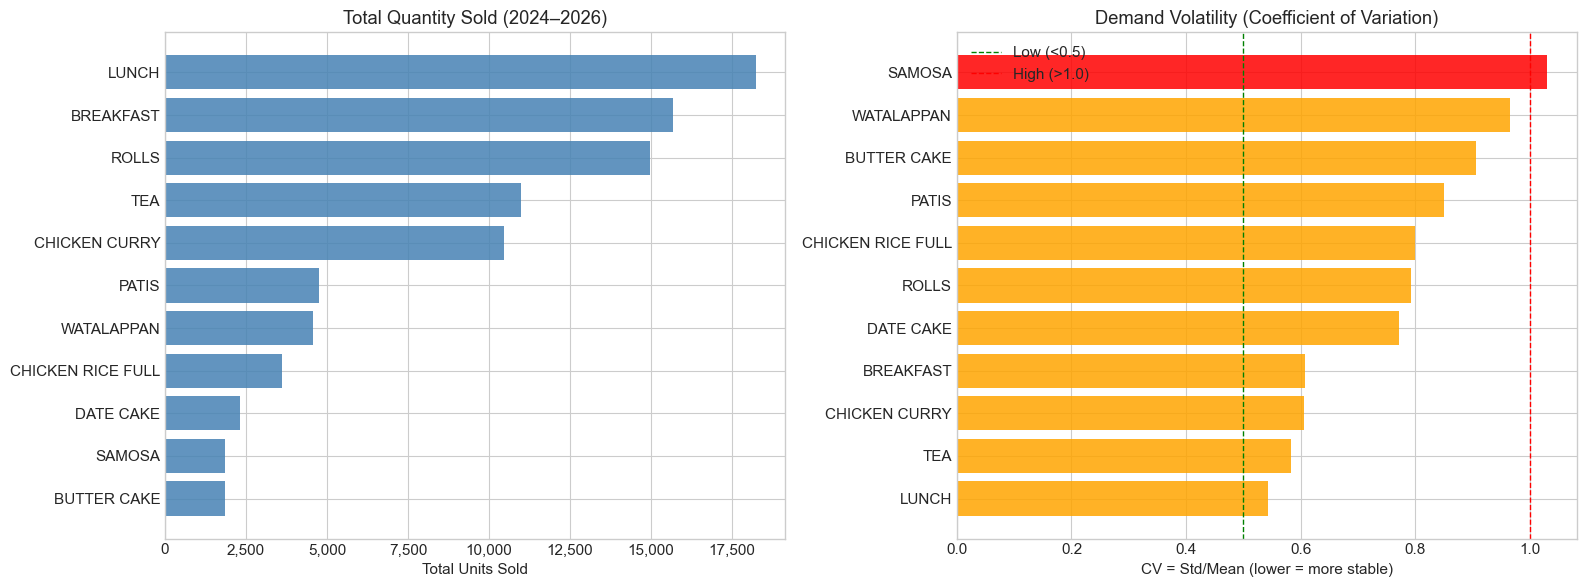


CV Interpretation:
  CV < 0.5  → Stable demand (easy to forecast)
  0.5–1.0   → Moderate volatility
  CV > 1.0  → High volatility (harder to forecast)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Total quantity sold
axes[0].barh(item_stats['ItemName'][::-1], item_stats['TotalQty'][::-1],
             color='steelblue', alpha=0.85)
axes[0].set_title('Total Quantity Sold (2024–2026)')
axes[0].set_xlabel('Total Units Sold')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Coefficient of Variation (demand volatility)
cv_sorted = item_stats.sort_values('CV', ascending=True)
colors_cv = ['green' if v < 0.5 else 'orange' if v < 1.0 else 'red' for v in cv_sorted['CV']]
axes[1].barh(cv_sorted['ItemName'], cv_sorted['CV'], color=colors_cv, alpha=0.85)
axes[1].axvline(0.5, color='green', linestyle='--', linewidth=1, label='Low (<0.5)')
axes[1].axvline(1.0, color='red', linestyle='--', linewidth=1, label='High (>1.0)')
axes[1].set_title('Demand Volatility (Coefficient of Variation)')
axes[1].set_xlabel('CV = Std/Mean (lower = more stable)')
axes[1].legend()

plt.tight_layout()
plt.show()

print("\nCV Interpretation:")
print("  CV < 0.5  → Stable demand (easy to forecast)")
print("  0.5–1.0   → Moderate volatility")
print("  CV > 1.0  → High volatility (harder to forecast)")

---
## 5. Per-Dish EDA Deep Dive

We examine the time series for each of the 11 dishes to understand seasonal patterns.

In [5]:
# Create full continuous calendar for all items
full_dates = pd.date_range(daily_demand['Date'].min(), daily_demand['Date'].max(), freq='D')
full_panel = pd.MultiIndex.from_product([full_dates, CORE_ITEMS], names=['Date', 'ItemName'])
panel_df = pd.DataFrame(index=full_panel).reset_index()

panel_df = panel_df.merge(daily_demand, on=['Date', 'ItemName'], how='left')
panel_df['Qty'] = panel_df['Qty'].fillna(0.0)

print(f"Panel shape: {panel_df.shape}  ({len(full_dates)} days × {len(CORE_ITEMS)} items)")
print(f"Zero-demand (date,item) pairs: {(panel_df['Qty'] == 0).sum():,}")

Panel shape: (9845, 3)  (895 days × 11 items)
Zero-demand (date,item) pairs: 2,052


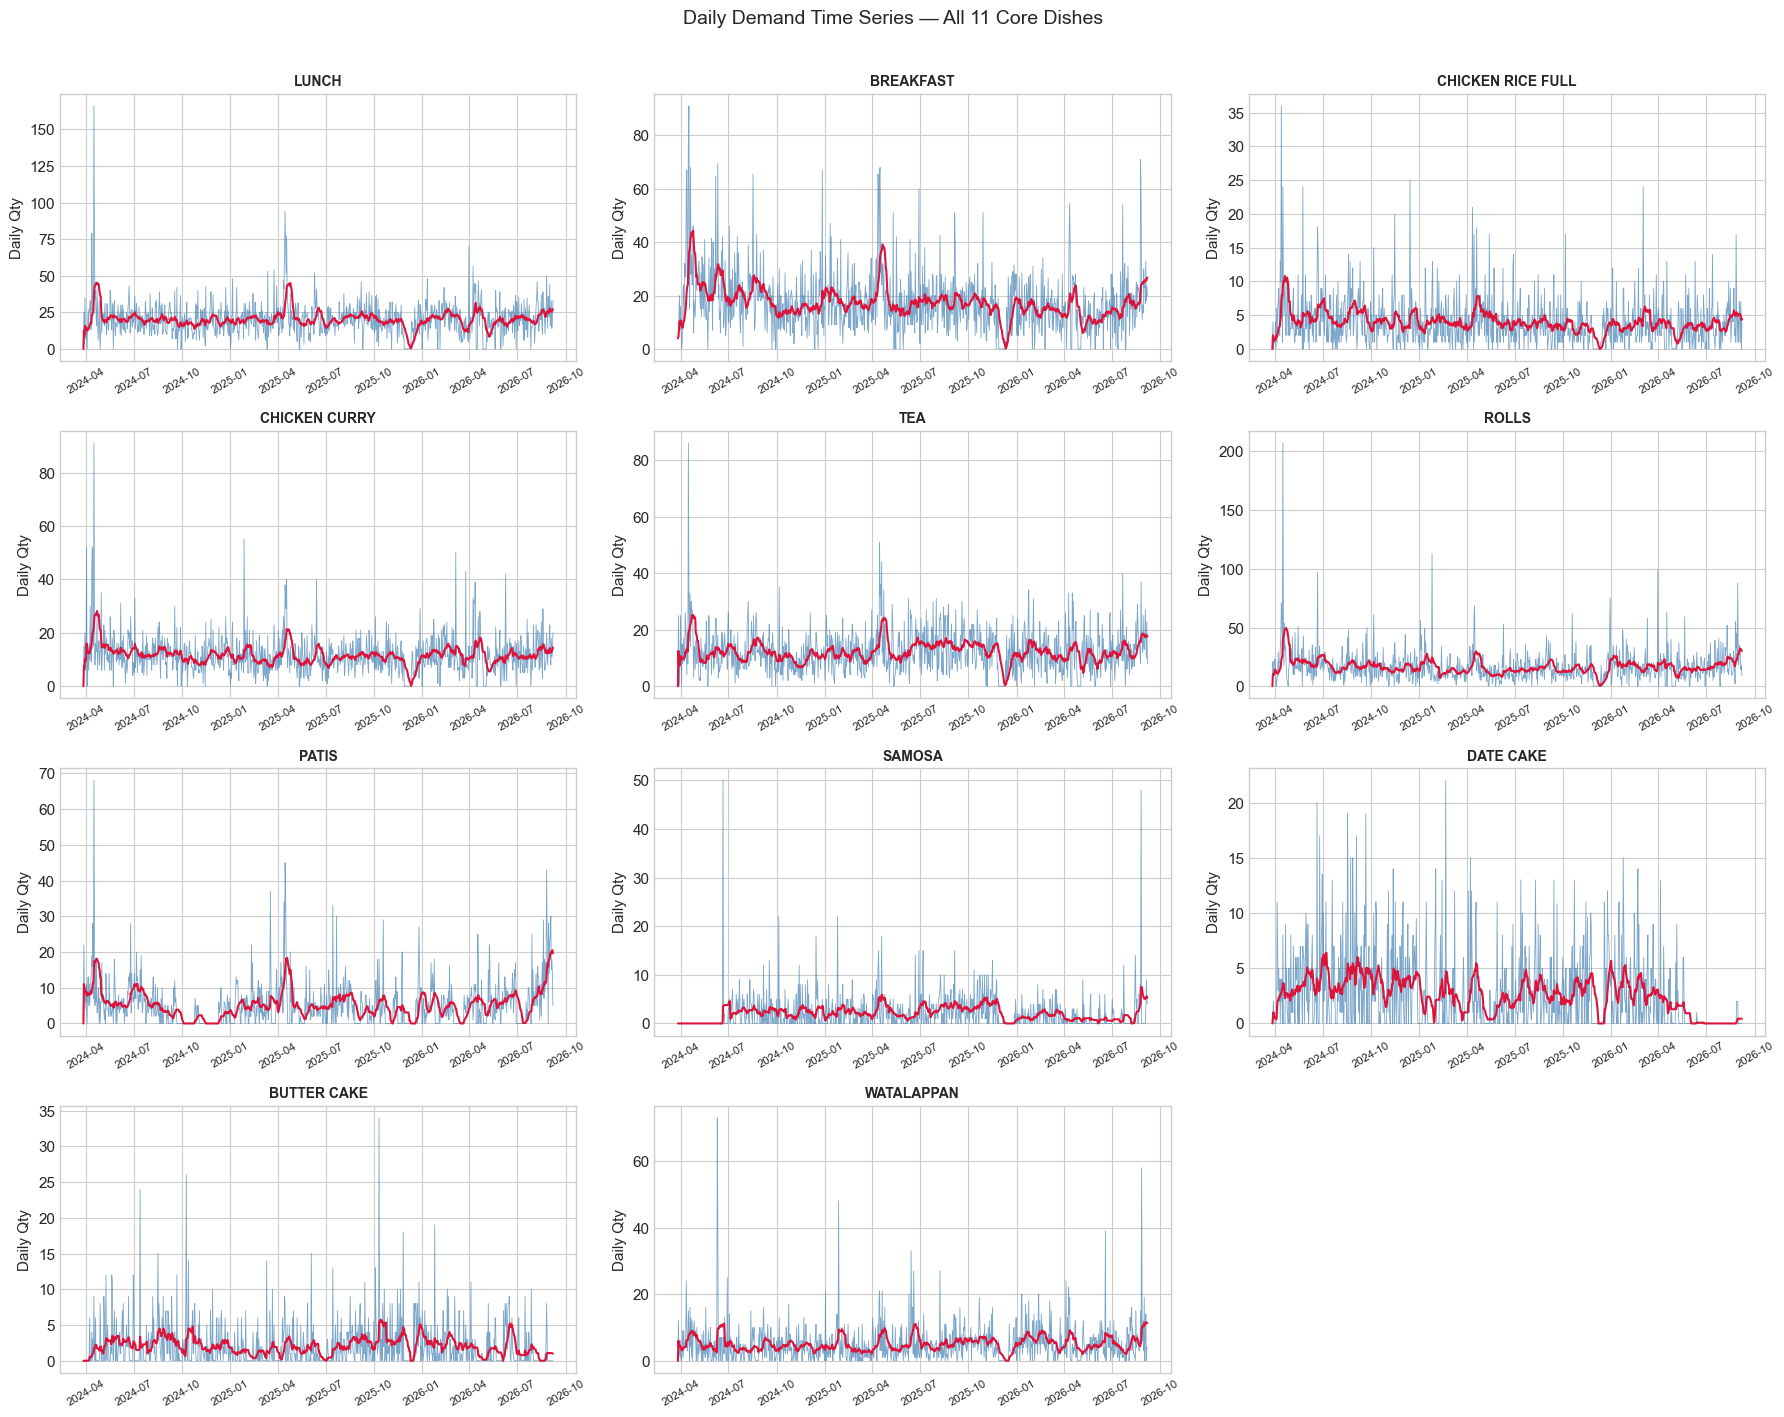

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(18, 14))
axes = axes.flatten()

for i, item in enumerate(CORE_ITEMS):
    ax = axes[i]
    item_data = panel_df[panel_df['ItemName'] == item].set_index('Date')['Qty']
    
    ax.plot(item_data.index, item_data.values, color='steelblue', linewidth=0.6, alpha=0.7)
    rolling = item_data.rolling(14, min_periods=1).mean()
    ax.plot(item_data.index, rolling, color='crimson', linewidth=1.5, label='14d mean')
    ax.set_title(item, fontsize=10, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Daily Qty')
    ax.tick_params(axis='x', rotation=30, labelsize=8)

# Hide unused subplot
for j in range(len(CORE_ITEMS), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Daily Demand Time Series — All 11 Core Dishes', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 5.1 Day-of-Week Demand Profile per Dish

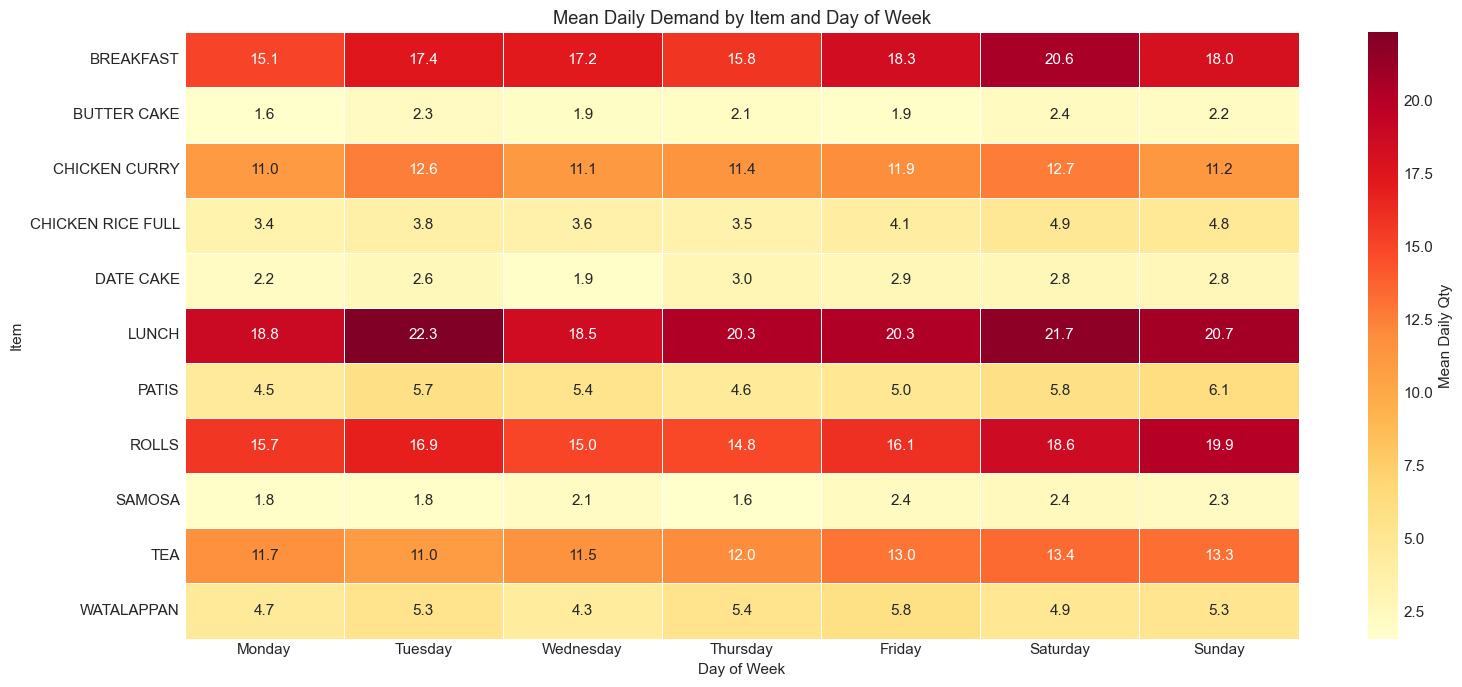


Interpretation:
Darker cells = higher demand on that day. Kitchen should prepare more on those days.


In [7]:
panel_df['DayOfWeek'] = panel_df['Date'].dt.day_name()
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

# Compute mean demand by DOW per item
dow_pivot = panel_df.groupby(['ItemName','DayOfWeek'])['Qty'].mean().unstack('DayOfWeek')[dow_order]

fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(dow_pivot, cmap='YlOrRd', annot=True, fmt='.1f', ax=ax,
            linewidths=0.5, cbar_kws={'label': 'Mean Daily Qty'})
ax.set_title('Mean Daily Demand by Item and Day of Week')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Item')
plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("Darker cells = higher demand on that day. Kitchen should prepare more on those days.")

---
## 6. Demand Stability Assessment

We check whether demand patterns are consistent across years (stability = model generalises well).

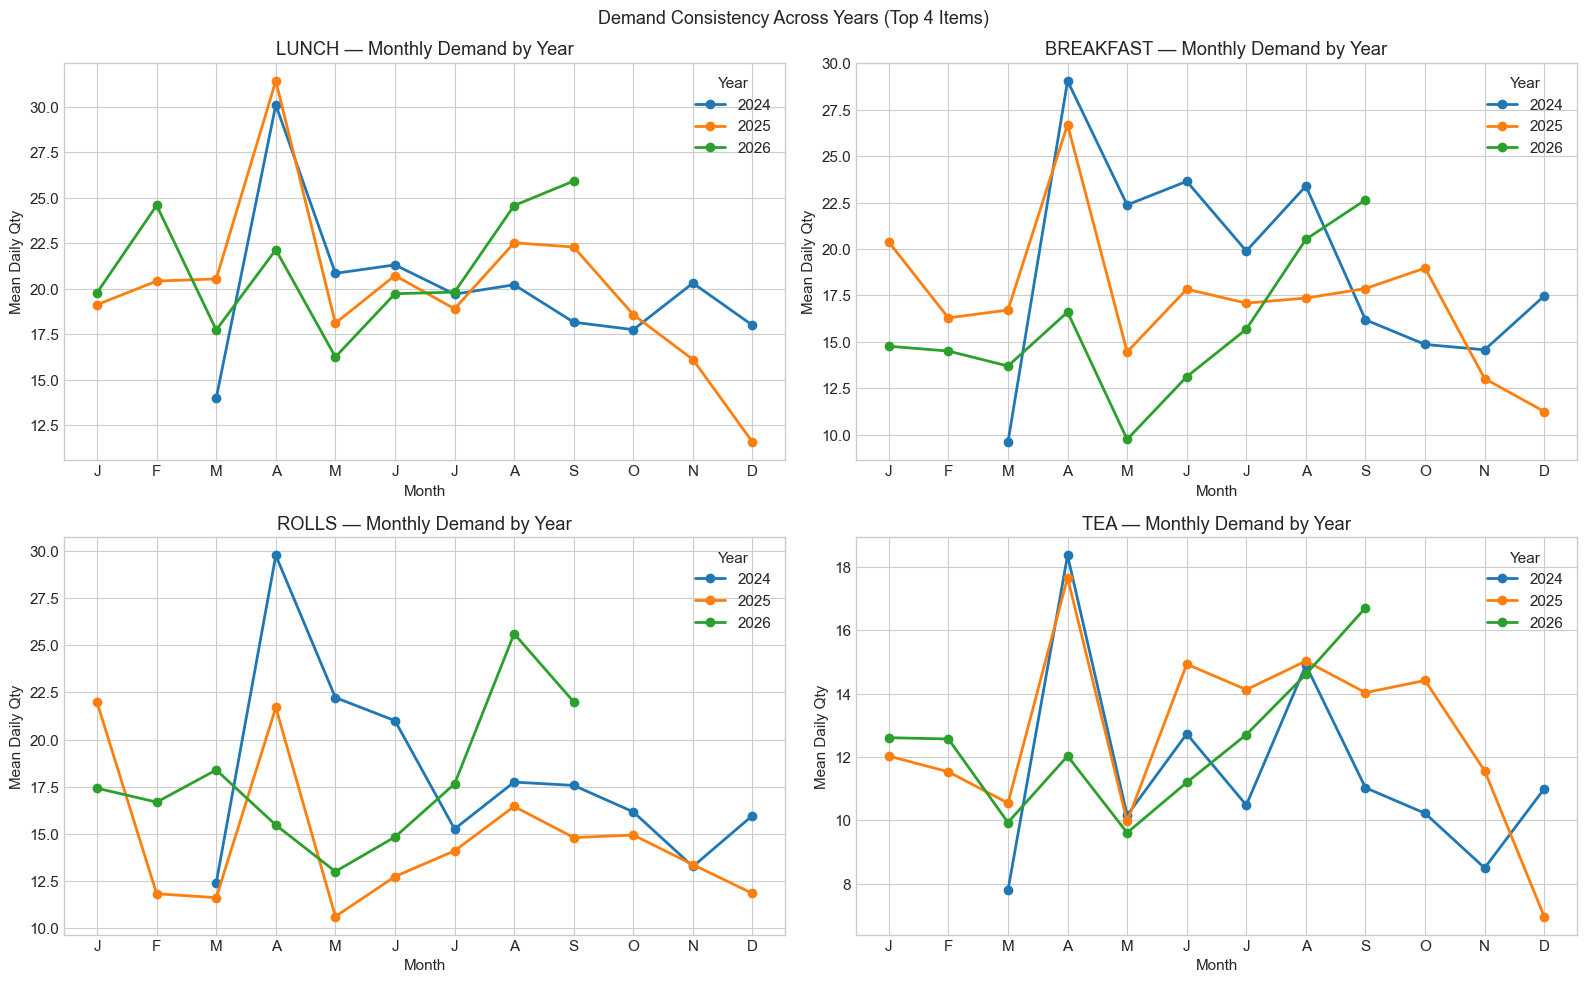

In [8]:
panel_df['Year'] = panel_df['Date'].dt.year
panel_df['Month'] = panel_df['Date'].dt.month

# Monthly demand comparison by year for top 4 items
top_items = item_stats.head(4)['ItemName'].tolist()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, item in enumerate(top_items):
    ax = axes[i]
    item_data = panel_df[panel_df['ItemName'] == item]
    monthly = item_data.groupby(['Year', 'Month'])['Qty'].mean().reset_index()
    
    for year in sorted(monthly['Year'].unique()):
        year_data = monthly[monthly['Year'] == year]
        ax.plot(year_data['Month'], year_data['Qty'], marker='o', label=str(year), linewidth=2)
    
    ax.set_title(f'{item} — Monthly Demand by Year')
    ax.set_xlabel('Month')
    ax.set_ylabel('Mean Daily Qty')
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
    ax.legend(title='Year')

plt.suptitle('Demand Consistency Across Years (Top 4 Items)', fontsize=13)
plt.tight_layout()
plt.show()

---
## 7. Panel Data Construction

We pivot from long-format to a panel suitable for machine learning: each row = one (date, item) observation.

In [9]:
# The panel_df already has the right structure
# Clean up intermediate columns
panel_clean = panel_df[['Date', 'ItemName', 'Qty']].copy()

print("Panel structure:")
print(panel_clean.head(20).to_string(index=False))
print(f"\nTotal (Date, Item) pairs: {len(panel_clean):,}")
print(f"Expected: {len(full_dates)} days × {len(CORE_ITEMS)} items = {len(full_dates)*len(CORE_ITEMS):,}")

Panel structure:
      Date          ItemName  Qty
2024-03-27             LUNCH  0.0
2024-03-27         BREAKFAST  4.0
2024-03-27 CHICKEN RICE FULL  0.0
2024-03-27     CHICKEN CURRY  0.0
2024-03-27               TEA  0.0
2024-03-27             ROLLS  0.0
2024-03-27             PATIS  0.0
2024-03-27            SAMOSA  0.0
2024-03-27         DATE CAKE  0.0
2024-03-27       BUTTER CAKE  0.0
2024-03-27        WATALAPPAN  0.0
2024-03-28             LUNCH 25.0
2024-03-28         BREAKFAST  5.0
2024-03-28 CHICKEN RICE FULL  4.0
2024-03-28     CHICKEN CURRY 15.0
2024-03-28               TEA 25.0
2024-03-28             ROLLS 21.0
2024-03-28             PATIS 22.0
2024-03-28            SAMOSA  0.0
2024-03-28         DATE CAKE  1.0

Total (Date, Item) pairs: 9,845
Expected: 895 days × 11 items = 9,845


In [10]:
# Zero-demand analysis per item
zero_analysis = panel_clean.groupby('ItemName').apply(
    lambda g: pd.Series({
        'TotalDays': len(g),
        'ZeroDays': (g['Qty'] == 0).sum(),
        'ZeroPct': (g['Qty'] == 0).mean() * 100
    })
).reset_index()
zero_analysis = zero_analysis.sort_values('ZeroPct', ascending=False)

print("Zero-Demand Day Analysis (% of days with zero sales):")
print(zero_analysis.to_string(index=False))
print("\nNote: High zero-demand % items require careful WAPE handling (WAPE handles zeros correctly).")

Zero-Demand Day Analysis (% of days with zero sales):
         ItemName  TotalDays  ZeroDays   ZeroPct
           SAMOSA      895.0     463.0 51.731844
      BUTTER CAKE      895.0     435.0 48.603352
        DATE CAKE      895.0     400.0 44.692737
            PATIS      895.0     281.0 31.396648
       WATALAPPAN      895.0     155.0 17.318436
CHICKEN RICE FULL      895.0     102.0 11.396648
        BREAKFAST      895.0      48.0  5.363128
            ROLLS      895.0      48.0  5.363128
            LUNCH      895.0      43.0  4.804469
    CHICKEN CURRY      895.0      39.0  4.357542
              TEA      895.0      38.0  4.245810

Note: High zero-demand % items require careful WAPE handling (WAPE handles zeros correctly).


---
## 8. Target Variable Definition

In [11]:
print("=" * 65)
print("LENS 2 — TARGET VARIABLE DEFINITION")
print("=" * 65)
print()
print("Target Variable: Qty")
print("Definition     : Total daily portion quantity sold for a specific")
print("                 menu item on a specific date")
print("Unit           : Integer portions (Qty >= 0)")
print("Scope          : 11 core fresh handmade dishes")
print("Time grain     : 1 calendar day")
print()
print("Panel structure: Each (Date, ItemName) pair is one prediction task.")
print(f"Observations   : {len(panel_clean):,}")
print(f"Date range     : {panel_clean['Date'].min().date()} → {panel_clean['Date'].max().date()}")
print()
print("Key characteristics:")
print(f"  Overall mean daily qty   : {panel_clean['Qty'].mean():.2f} portions")
print(f"  Overall median daily qty : {panel_clean['Qty'].median():.2f} portions")
print(f"  Overall std dev          : {panel_clean['Qty'].std():.2f} portions")
print(f"  Max single-day, single-item: {panel_clean['Qty'].max():.0f} portions")

LENS 2 — TARGET VARIABLE DEFINITION

Target Variable: Qty
Definition     : Total daily portion quantity sold for a specific
                 menu item on a specific date
Unit           : Integer portions (Qty >= 0)
Scope          : 11 core fresh handmade dishes
Time grain     : 1 calendar day

Panel structure: Each (Date, ItemName) pair is one prediction task.
Observations   : 9,845
Date range     : 2024-03-27 → 2026-09-07

Key characteristics:
  Overall mean daily qty   : 9.06 portions
  Overall median daily qty : 6.00 portions
  Overall std dev          : 10.46 portions
  Max single-day, single-item: 207 portions


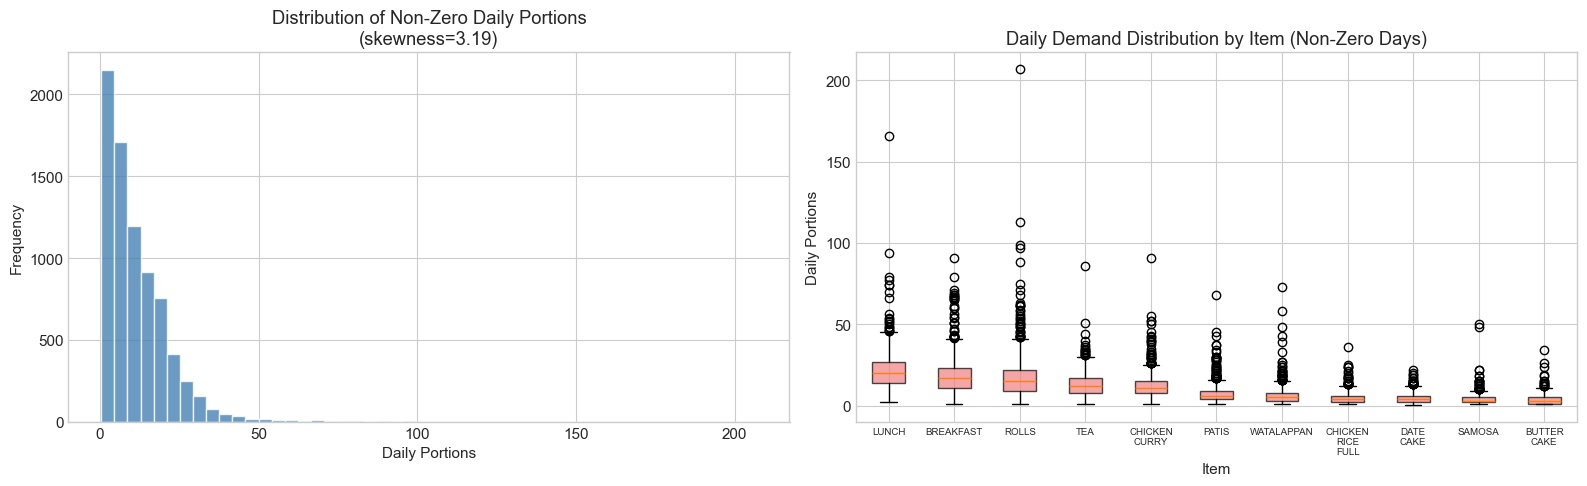

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Overall distribution (non-zero)
nonzero_qty = panel_clean[panel_clean['Qty'] > 0]['Qty']
axes[0].hist(nonzero_qty, bins=50, color='steelblue', alpha=0.8, edgecolor='white')
axes[0].set_title(f'Distribution of Non-Zero Daily Portions\n(skewness={stats.skew(nonzero_qty):.2f})')
axes[0].set_xlabel('Daily Portions')
axes[0].set_ylabel('Frequency')

# Per-item box plots
nonzero_panel = panel_clean[panel_clean['Qty'] > 0]
item_order = item_stats['ItemName'].tolist()
box_data = [nonzero_panel[nonzero_panel['ItemName'] == item]['Qty'].values for item in item_order]

bp = axes[1].boxplot(box_data, labels=[item.replace(' ', '\n') for item in item_order],
                     patch_artist=True,
                     boxprops=dict(facecolor='lightcoral', alpha=0.7))
axes[1].set_title('Daily Demand Distribution by Item (Non-Zero Days)')
axes[1].set_xlabel('Item')
axes[1].set_ylabel('Daily Portions')
axes[1].tick_params(axis='x', labelsize=7)

plt.tight_layout()
plt.show()

### 8.1 Save Panel Data

In [13]:
# Save long-format panel
PANEL_PATH = '../data/processed/daily_product_demand_long.csv'
panel_clean.to_csv(PANEL_PATH, index=False)
print(f"Saved long-format panel: {PANEL_PATH}  ({len(panel_clean):,} rows)")

# Save wide-format (date × item)
panel_wide = panel_clean.pivot(index='Date', columns='ItemName', values='Qty').reset_index()
WIDE_PATH = '../data/processed/daily_product_demand.csv'
panel_wide.to_csv(WIDE_PATH, index=False)
print(f"Saved wide-format panel : {WIDE_PATH}  ({panel_wide.shape})")  

Saved long-format panel: ../data/processed/daily_product_demand_long.csv  (9,845 rows)
Saved wide-format panel : ../data/processed/daily_product_demand.csv  ((895, 12))


---
## 9. EDA Summary & Decision Log

| # | Insight | Evidence | Decision |
|---|---|---|---|
| 1 | LUNCH and BREAKFAST have the highest total demand | Pareto chart | Keep both; they dominate kitchen workload |
| 2 | WATALAPPAN shows high volatility (CV>1.0) | CV analysis | Include but expect lower forecast accuracy |
| 3 | All dishes show day-of-week pattern | Heatmap | DOW encoding essential for Lens 2 features |
| 4 | Some dishes have 20–40% zero-demand days | Zero analysis | Use WAPE (handles zeros); add `is_closed` flag |
| 5 | Demand is right-skewed for all dishes | Distribution plots | Monitor; Poisson or log-normal link possible |
| 6 | Panel model preferred over 11 separate models | Data volume analysis | Shared seasonality learned more efficiently jointly |

---
## 10. Responsible AI Declaration

### Ethical Considerations in Kitchen Demand Forecasting

| Risk | Detail | Mitigation |
|---|---|---|
| **Over-preparation bias** | If model systematically over-predicts, kitchen prepares too much → food waste | Use asymmetric evaluation; report bias direction in residuals |
| **Under-preparation bias** | Systematic under-prediction → stockouts → unhappy customers | Apply asymmetric Kitchen Risk Buffer (NB08) |
| **Waste of perishable food** | Inaccurate predictions contribute to food waste, a sustainability issue | Frame model as decision support, not decision replacement |
| **Over-reliance on AI** | Kitchen staff might stop using judgment, causing errors when model fails | Clearly communicate model uncertainty (confidence intervals) |

### AI-use Declaration (IT24102726)
This notebook was authored by the student. AI tools were used only for markdown formatting. All analytical decisions, EDA interpretations, and business framing are the author's own work.